# Phân tích & dự báo chuỗi thời gian COVID-19

Notebook này chạy trọn quy trình của package `covid_forecast`: từ tải dữ liệu thô của
JHU CSSE → phân tích chuỗi → sinh đặc trưng → huấn luyện ~15 mô hình → đánh giá trung
thực bằng backtest → dự báo tương lai.

**Cấu trúc thư mục cần có** (package dùng import tương đối nên bắt buộc phải nằm trong
một thư mục package, không chạy lẻ từng file):

```
project/
├── covid_forecast/          ← 9 file .py (config, data, analysis, features,
│   ├── __init__.py            metrics, models, backtest, plots)
│   ├── config.py
│   └── ...
├── data/raw/                ← tự tạo, cache CSV của JHU
├── outputs/figures/         ← tự tạo, nơi lưu hình
├── outputs/results/         ← tự tạo, nơi lưu bảng kết quả
└── covid_forecast_demo.ipynb   ← notebook này
```

**Thư viện bắt buộc:** `numpy pandas matplotlib scipy statsmodels scikit-learn`
**Tuỳ chọn** (thiếu thì notebook tự bỏ qua mô hình tương ứng): `xgboost`, `torch`, `prophet`

```bash
pip install numpy pandas matplotlib scipy statsmodels scikit-learn
pip install xgboost torch prophet   # tuỳ chọn
```

## 0. Nạp thư viện & cấu hình

In [2]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Cho phép chạy notebook từ thư mục gốc của project (chứa thư mục covid_forecast/)
ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from covid_forecast import analysis, backtest, data, features, metrics, models, plots
from covid_forecast.config import OUT_RES

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120, "display.max_columns", 40)
plots.use_style()          # áp dụng style chung cho toàn bộ hình

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.4.6


In [3]:
# ------------------------------------------------------------------ THAM SỐ
COUNTRY  = "Vietnam"       # None = toàn cầu; xem data.list_countries() để biết tên hợp lệ
METRIC   = "confirmed"     # confirmed | deaths | recovered
START    = "2021-06-01"    # cắt giai đoạn phân tích (Delta + Omicron ở VN)
END      = "2022-08-31"
SMOOTH   = None            # None = dữ liệu thô; 7 = trung bình trượt 7 ngày (xem cảnh báo §1)
HORIZON  = 14              # số ngày dự báo
N_SPLITS = 5               # số điểm cắt cho rolling-origin backtest
FAST     = True            # True = bỏ Auto-ARIMA, giảm số cây -> chạy nhanh hơn nhiều

# Tự phát hiện thư viện tuỳ chọn
def _has(mod: str) -> bool:
    try:
        __import__(mod); return True
    except Exception:
        return False

USE_PROPHET, USE_LSTM = _has("prophet"), _has("torch")
print(f"prophet: {USE_PROPHET} | torch (LSTM): {USE_LSTM} | xgboost: {_has('xgboost')}")

prophet: False | torch (LSTM): False | xgboost: False


## 1. Dữ liệu

Định dạng gốc của JHU là *wide*: mỗi dòng là một vùng lãnh thổ, mỗi cột từ cột thứ 5 trở
đi là một ngày, giá trị là **số ca luỹ kế**. Ba bước xử lý:

1. `country_series` – lọc quốc gia, cộng dồn các tỉnh/bang, đổi cột ngày thành `DatetimeIndex`
2. `to_daily_new` – sai phân bậc 1 để ra **số ca mới mỗi ngày** (cắt giá trị âm về 0, vì các
   đợt điều chỉnh số liệu hồi tố tạo ra ngày âm)
3. `load_target` – gói cả hai bước trên + cắt giai đoạn + nội suy ngày thiếu

> **Lưu ý:** bộ dữ liệu JHU đã ngừng cập nhật từ 09/03/2023, nên `END` không thể vượt mốc này.

In [4]:
cum = data.load_target(country=COUNTRY, metric=METRIC, kind="cumulative",
                       start=START, end=END)
y   = data.load_target(country=COUNTRY, metric=METRIC, kind="daily",
                       start=START, end=END, smooth_window=SMOOTH)

print(f"Chuỗi mục tiêu: {y.name} | {len(y)} quan sát")
data.describe_series(y).to_frame("giá trị")

[data] Dang tai https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv
Chuỗi mục tiêu: confirmed_daily | 457 quan sát


,giá trị
so_quan_sat,457
bat_dau,2021-06-01
ket_thuc,2022-08-31
tan_suat,D
thieu_du_lieu,0
trung_binh,24954.588621
do_lech_chuan,57688.969169
nho_nhat,0.0
lon_nhat,454212.0
ngay_dinh_diem,2022-03-12


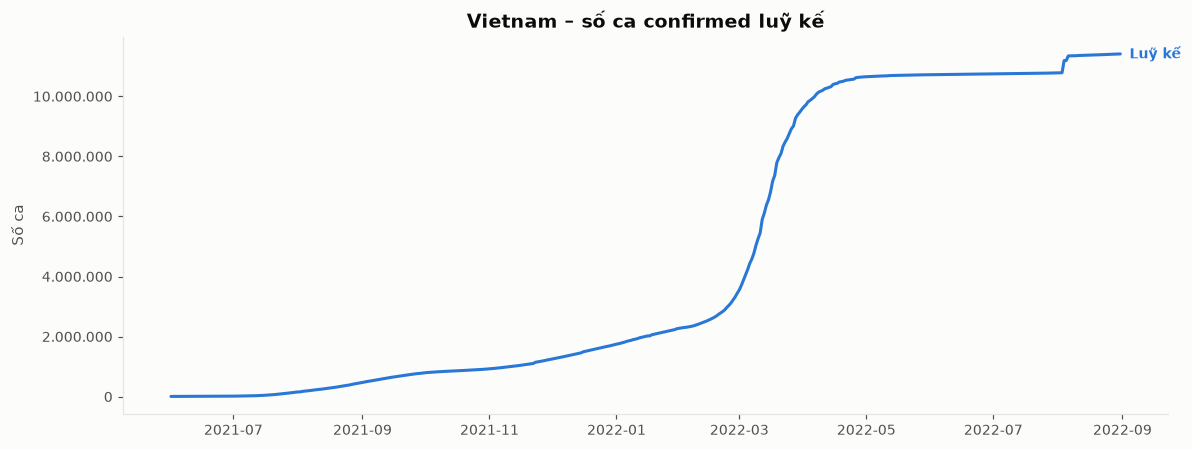

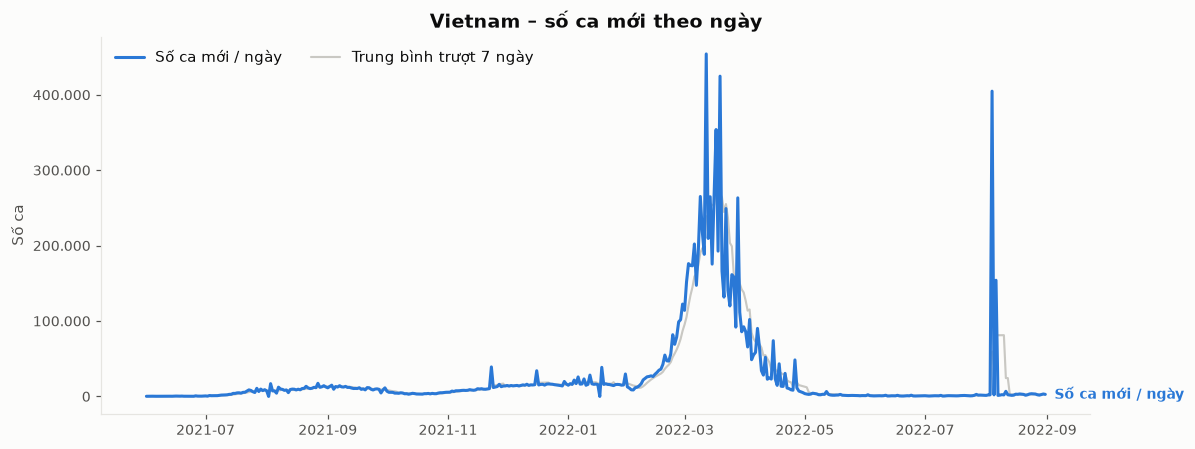

In [5]:
fig = plots.plot_series(
    {"Luỹ kế": cum},
    title=f"{COUNTRY} – số ca {METRIC} luỹ kế", ylabel="Số ca")
fig = plots.plot_series(
    {"Số ca mới / ngày": y, "Trung bình trượt 7 ngày": data.smooth(y, 7)},
    title=f"{COUNTRY} – số ca mới theo ngày", ylabel="Số ca", highlight="Số ca mới / ngày")

In [6]:
# Ngày nào có số liệu bất thường? (thường là dồn báo cáo hồi tố, không phải diễn biến dịch)
med = y.rolling(14, center=True, min_periods=5).median()
sd  = y.rolling(14, center=True, min_periods=5).std().replace(0, np.nan)
((y - med).abs() / sd).sort_values(ascending=False).head(5).to_frame("lệch (số lần std)")

,lệch (số lần std)
2021-12-16,3.736013
2021-11-23,3.678971
2022-08-04,3.591771
2022-06-02,3.277836
2022-04-26,3.174550


Hai điều đọc được ngay từ hình:

- **Biên độ thay đổi cực lớn** giữa các giai đoạn (đáy vài trăm ca, đỉnh vài trăm nghìn ca).
  Mọi chỉ số sai số theo đơn vị gốc (MAE, RMSE) sẽ bị chi phối hoàn toàn bởi giai đoạn đỉnh.
- **Răng cưa theo tuần**: cuối tuần ít ca hơn — đây là hiệu ứng *báo cáo*, không phải hiệu ứng
  dịch tễ. Đó là lý do chu kỳ mùa vụ được đặt `m = 7`.

⚠️ Nếu bật `SMOOTH = 7`, mọi mô hình sẽ trông chính xác hơn hẳn — nhưng đó là vì bài toán
đã bị làm dễ đi (đã khử sẵn phần nhiễu khó đoán nhất), **không phải** vì mô hình tốt hơn.
Khi báo cáo kết quả phải nói rõ đã làm trơn hay chưa.

## 2. Phân tích chuỗi (Box–Jenkins)

Bốn bước chuẩn trước khi mô hình hoá: phân rã → kiểm tra tính dừng → biến đổi cho dừng →
xác định bậc mô hình qua ACF/PACF.

### 2.1 Phân rã STL: xu thế / mùa vụ / phần dư

{'do_manh_xu_the': np.float64(0.794), 'do_manh_mua_vu': 0.0}

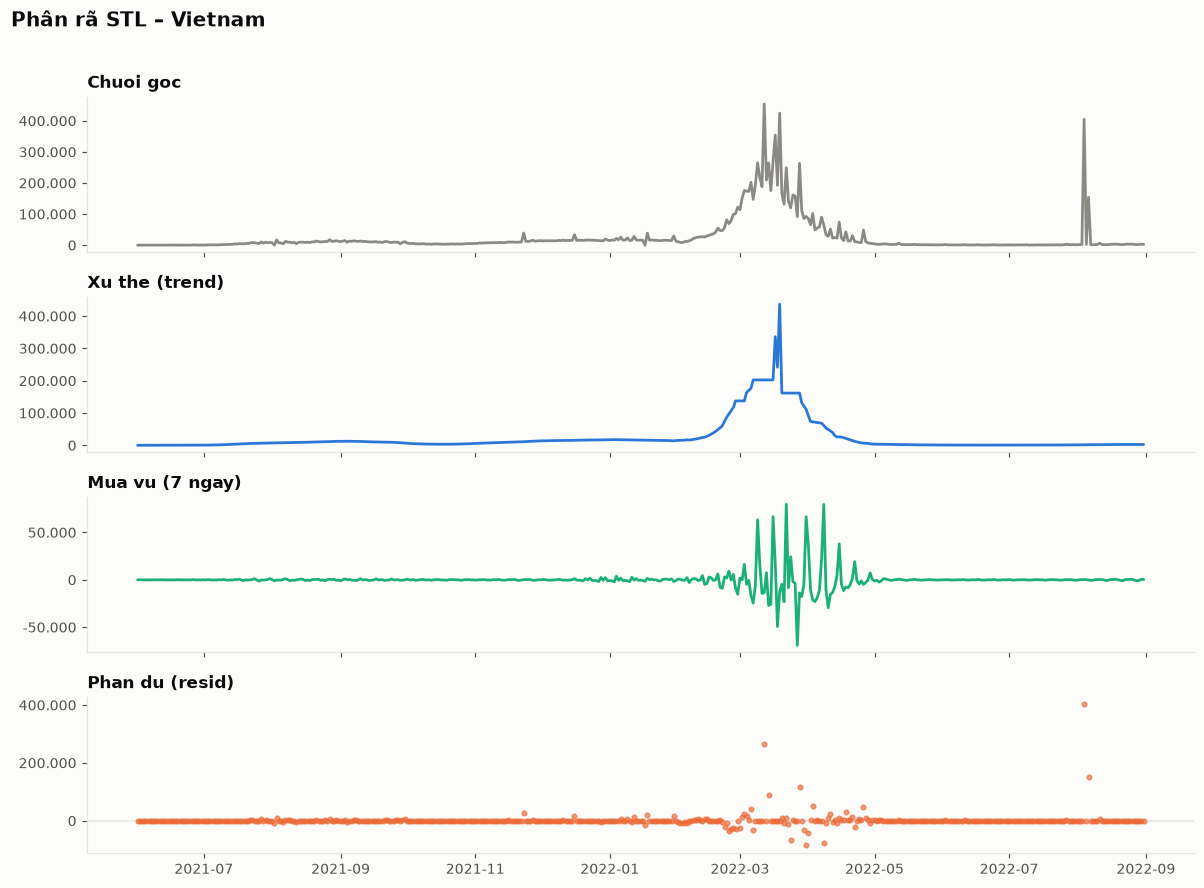

In [7]:
decomp = analysis.decompose(y, method="stl")
fig = plots.plot_decomposition(decomp, title=f"Phân rã STL – {COUNTRY}")
analysis.seasonal_strength(y)

Chỉ số Wang–Smith–Hyndman nằm trong \[0, 1\]: càng gần 1 thì thành phần đó càng rõ.
Độ mạnh xu thế cao (~0.9) nghĩa là chuỗi chủ yếu là **các đợt sóng**, còn mùa vụ tuần
chỉ là dao động phụ chồng lên trên.

### 2.2 Tính dừng: ADF & KPSS

In [8]:
analysis.stationarity_report(y)

,kiem_dinh,thong_ke,p_value,so_tre,gia_tri_toi_han_5%,ket_luan
0,ADF,-3.0312,0.032085,12,-2.8681,DUNG (stationary)
1,KPSS,0.3609,0.094029,12,0.4630,DUNG (stationary)


Bậc sai phân đề xuất (theo ADF): 0


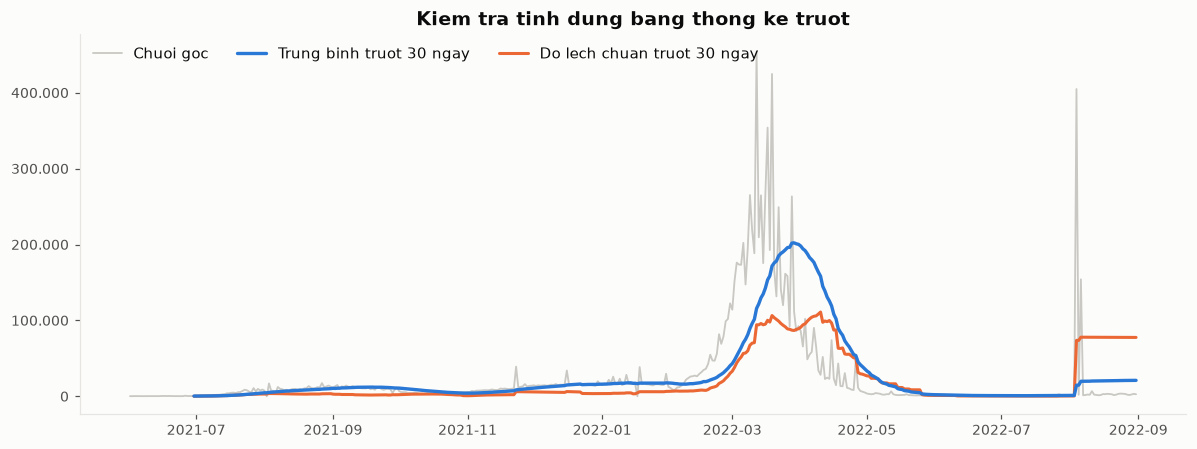

In [9]:
fig = plots.plot_rolling_stats(y, window=30)
print("Bậc sai phân đề xuất (theo ADF):", analysis.suggest_differencing(y))

**Đọc kết quả thế nào:** hai kiểm định có giả thuyết H0 **ngược nhau** nên cần đọc cặp:

| ADF | KPSS | Kết luận |
|---|---|---|
| dừng | dừng | chuỗi dừng, không cần sai phân |
| không dừng | không dừng | cần sai phân |
| dừng | không dừng | mâu thuẫn → thường là *trend-stationary*, thử khử xu thế |
| không dừng | dừng | mâu thuẫn → thường là *difference-stationary* |

Trên chuỗi COVID thường rơi vào ô mâu thuẫn: phương sai thay đổi mạnh theo giai đoạn
(heteroskedasticity) làm cả hai kiểm định đều kém tin cậy. Hình trung bình/độ lệch chuẩn
trượt ở trên cho thấy rõ điều đó — độ lệch chuẩn trượt nhảy vọt ở vùng đỉnh dịch.

### 2.3 ACF / PACF – gợi ý bậc cho ARIMA

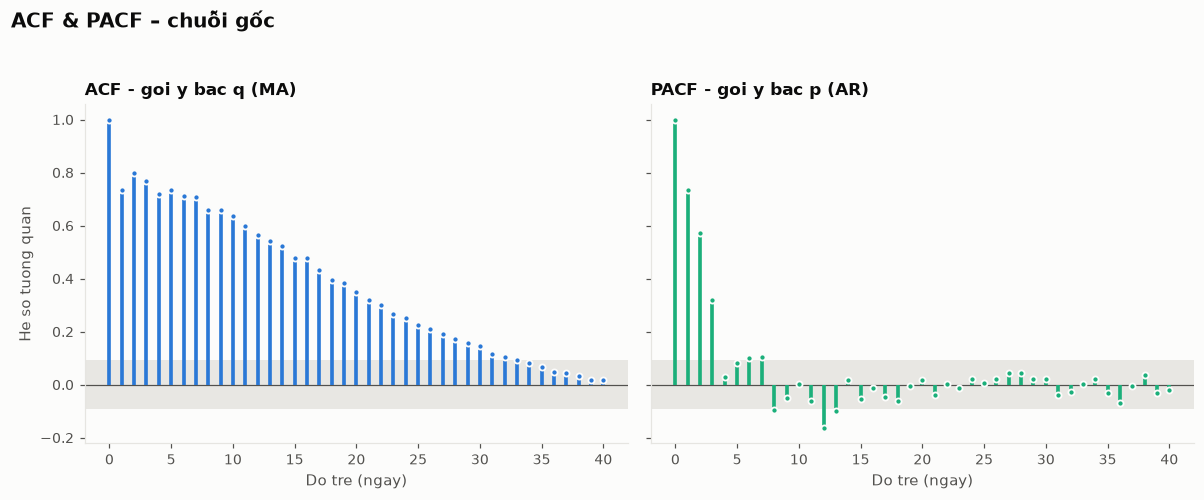

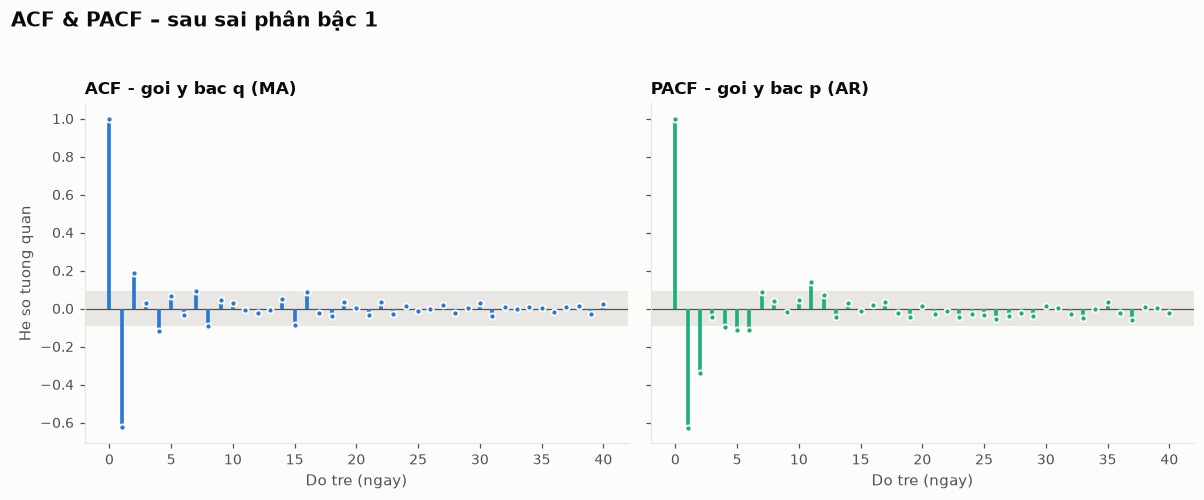

In [10]:
acf_tbl = analysis.acf_pacf(y, nlags=40)
fig = plots.plot_acf_pacf(acf_tbl, title="ACF & PACF – chuỗi gốc")

d1 = analysis.difference(y, order=1)
fig = plots.plot_acf_pacf(analysis.acf_pacf(d1, nlags=40),
                          title="ACF & PACF – sau sai phân bậc 1")

Quy tắc đọc nhanh: **PACF** tắt đột ngột sau lag *p* → gợi ý AR(*p*); **ACF** tắt đột ngột
sau lag *q* → gợi ý MA(*q*). Nếu ACF của chuỗi gốc giảm rất chậm (gần như tuyến tính) thì
chuỗi chưa dừng → phải sai phân trước. Các gai tại lag 7, 14, 21 là dấu hiệu mùa vụ tuần
→ cần thành phần SARIMA `(P, D, Q, 7)`.

## 3. Sinh đặc trưng cho mô hình học máy

Ridge, Random Forest, XGBoost… không hiểu khái niệm "thời gian". Phải tự tay biến chuỗi
$y(t)$ thành bảng $X \to y$:

$$y(t) = f\big(y(t-1),\; \dots,\; y(t-p),\; \text{trung bình trượt},\; \text{thứ trong tuần},\; \dots\big)$$

Điểm mấu chốt để **không rò rỉ dữ liệu tương lai**: mọi đặc trưng trượt đều tính trên
`y.shift(1)`, tức chỉ nhìn vào quá khứ tính đến ngày *t−1*.

In [11]:
feat = features.make_lag_features(y)
X, y_sup = features.supervised_split(feat)

print(f"{X.shape[1]} đặc trưng, {len(X)} dòng dùng được "
      f"(mất {len(feat) - len(X)} dòng đầu do lag dài nhất = {max(features.DEFAULT_LAGS)})")
X.iloc[:5, :8]

30 đặc trưng, 429 dòng dùng được (mất 28 dòng đầu do lag dài nhất = 28)


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_14
2021-06-29,396.0,415.0,788.0,214.0,334.0,207.0,252.0,423.0
2021-06-30,371.0,396.0,415.0,788.0,214.0,334.0,207.0,490.0
2021-07-01,545.0,371.0,396.0,415.0,788.0,214.0,334.0,356.0
2021-07-02,675.0,545.0,371.0,396.0,415.0,788.0,214.0,358.0
2021-07-03,394.0,675.0,545.0,371.0,396.0,415.0,788.0,470.0


In [12]:
# Đặc trưng nào tương quan mạnh nhất với mục tiêu?
corr = X.corrwith(y_sup).abs().sort_values(ascending=False)
corr.head(12).to_frame("|tương quan| với y")

,|tương quan| với y
roll_mean_3,0.837206
roll_mean_7,0.831857
lag_2,0.798842
roll_mean_14,0.777188
lag_3,0.766172
roll_max_3,0.750477
lag_5,0.731744
lag_1,0.731265
lag_4,0.716735
lag_6,0.710725


Kết quả dễ đoán nhưng đáng chú ý: `lag_1` và `roll_mean_3` gần như luôn đứng đầu. Nói cách
khác, phần lớn thông tin dự báo nằm ở **giá trị hôm qua** — đây chính là lý do mô hình Naive
rất khó bị đánh bại (xem §6).

## 4. Chạy thử một mô hình

Mọi mô hình dùng chung giao diện kiểu scikit-learn:

```python
model.fit(y_train)            # y_train: pd.Series có DatetimeIndex
model.predict(horizon)        # pd.Series cho horizon ngày kế tiếp
model.predict_interval(h)     # DataFrame lower / mean / upper (nếu hỗ trợ)
```

`backtest.holdout` cắt chuỗi một lần theo thứ tự thời gian: `[==== train ====][= test =]`.
Tuyệt đối **không** dùng K-Fold ngẫu nhiên cho chuỗi thời gian — làm vậy là cho mô hình
nhìn thấy tương lai rồi bắt nó đoán quá khứ.

In [13]:
sarima = models.ARIMAForecaster((1, 1, 1), (1, 0, 1, 7),
                                label="SARIMA(1,1,1)x(1,0,1,7)")
kq = backtest.holdout(sarima, y, test_size=HORIZON)

print(f"{kq['ten']}  —  {kq['giay']}s")
pd.Series(kq["chi_so"]).round(3).to_frame("giá trị")

SARIMA(1,1,1)x(1,0,1,7)  —  0.28s


,giá trị
MAE,1159.546
RMSE,1328.147
MAPE,40.217
sMAPE,53.102
R2,-3.624
MASE,0.083
Bias,1159.546
Coverage95,100.000


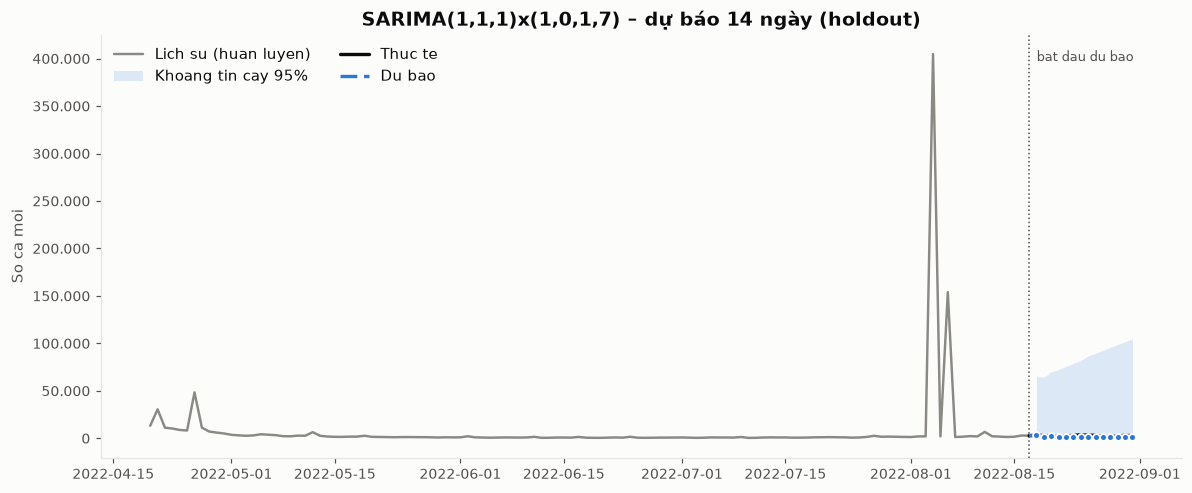

In [14]:
fig = plots.plot_forecast(kq["train"], kq["thuc_te"], kq["du_bao"],
                          interval=kq["khoang_tin_cay"],
                          title=f"{kq['ten']} – dự báo {HORIZON} ngày (holdout)")

**Ý nghĩa các chỉ số** (chi tiết trong `metrics.py`):

- `MAE` / `RMSE` – cùng đơn vị với dữ liệu; RMSE phạt nặng sai số lớn
- `MAPE` – sai số tương đối (%), **vô nghĩa khi giá trị thực = 0** (rất hay gặp ở dữ liệu dịch)
- `MASE` – sai số chia cho sai số của mô hình naive mùa vụ trên tập train.
  **`MASE < 1` = tốt hơn naive.** Đây là chỉ số an toàn nhất cho dữ liệu này.
- `Bias > 0` – mô hình dự báo **thấp hơn** thực tế
- `Coverage95` – % giá trị thực rơi vào khoảng tin cậy; lý tưởng là ~95%

## 5. So sánh toàn bộ danh mục mô hình (holdout)

Bốn nhóm: baseline (Naive, Seasonal Naive, Mean, Drift) → thống kê (ETS, Theta, ARIMA,
SARIMA, Auto-ARIMA, Prophet) → học máy (Ridge, KNN, RF, GB, SVR, XGBoost) → deep (LSTM).

Nhóm baseline **bắt buộc phải có**: một mô hình phức tạp mà không thắng nổi Naive thì
không có lý do gì để dùng.

In [15]:
danh_muc = models.default_models(fast=FAST, use_prophet=USE_PROPHET, use_lstm=USE_LSTM)
print(f"{len(danh_muc)} mô hình:")
for i, ten in enumerate(danh_muc, 1):
    print(f"  {i:2d}. {ten}")

15 mô hình:
   1. Naive (gia tri hom qua)
   2. Seasonal Naive (tuan truoc)
   3. Trung binh truot 7 ngay
   4. Drift (ngoai suy tuyen tinh)
   5. SES (lam tron ham mu don gian)
   6. Holt (xu the tuyen tinh)
   7. Holt-Winters (mua vu 7 ngay)
   8. Theta
   9. ARIMA(2, 1, 2)
  10. SARIMA(1,1,1)x(1,0,1,7)
  11. Ridge (hoi quy tuyen tinh)
  12. K-Nearest Neighbors
  13. Random Forest
  14. Gradient Boosting
  15. SVR (RBF kernel)


In [16]:
kq_holdout = backtest.compare_holdout(danh_muc, y, test_size=HORIZON, sort_by="RMSE")
kq_holdout["bang"]

  [v] Naive (gia tri hom qua)                    RMSE=    621.69  MASE= 0.038  (0.0s)
  [v] Seasonal Naive (tuan truoc)                RMSE=   1415.27  MASE= 0.066  (0.0s)
  [v] Trung binh truot 7 ngay                    RMSE=    621.77  MASE= 0.038  (0.0s)
  [v] Drift (ngoai suy tuyen tinh)               RMSE=    631.00  MASE= 0.038  (0.0s)
  [v] SES (lam tron ham mu don gian)             RMSE=   1835.42  MASE= 0.123  (0.04s)
  [v] Holt (xu the tuyen tinh)                   RMSE=   1945.38  MASE= 0.132  (0.03s)
  [v] Holt-Winters (mua vu 7 ngay)               RMSE=   2676.92  MASE= 0.183  (0.14s)
  [v] Theta                                      RMSE=   5261.19  MASE= 0.240  (0.11s)
  [v] ARIMA(2, 1, 2)                             RMSE=   1040.02  MASE= 0.062  (0.11s)
  [v] SARIMA(1,1,1)x(1,0,1,7)                    RMSE=   1328.15  MASE= 0.083  (0.12s)
  [v] Ridge (hoi quy tuyen tinh)                 RMSE=  86740.30  MASE= 5.787  (0.14s)
  [v] K-Nearest Neighbors                      

,MAE,RMSE,MAPE,sMAPE,R2,MASE,Bias,Coverage95,Giay
Mo hinh,,,,,,,,,
Naive (gia tri hom qua),528.786,621.690,22.994,20.185,-0.013,0.038,-70.929,100.000,0.00
Trung binh truot 7 ngay,528.786,621.771,23.000,20.185,-0.013,0.038,-71.643,100.000,0.00
Drift (ngoai suy tuyen tinh),534.292,630.996,23.548,20.361,-0.044,0.038,-115.403,100.000,0.00
"ARIMA(2, 1, 2)",868.149,1040.020,32.369,35.715,-1.835,0.062,484.942,100.000,0.11
"SARIMA(1,1,1)x(1,0,1,7)",1159.546,1328.147,40.217,53.102,-3.624,0.083,1159.546,100.000,0.12
Seasonal Naive (tuan truoc),927.786,1415.274,31.033,28.173,-4.251,0.066,-71.643,100.000,0.00
SES (lam tron ham mu don gian),1728.382,1835.421,73.562,49.846,-7.831,0.123,-1728.382,100.000,0.04
Holt (xu the tuyen tinh),1842.753,1945.385,78.026,52.166,-8.921,0.132,-1842.753,100.000,0.03
Holt-Winters (mua vu 7 ngay),2558.075,2676.922,94.386,187.426,-17.785,0.183,2558.075,100.000,0.14


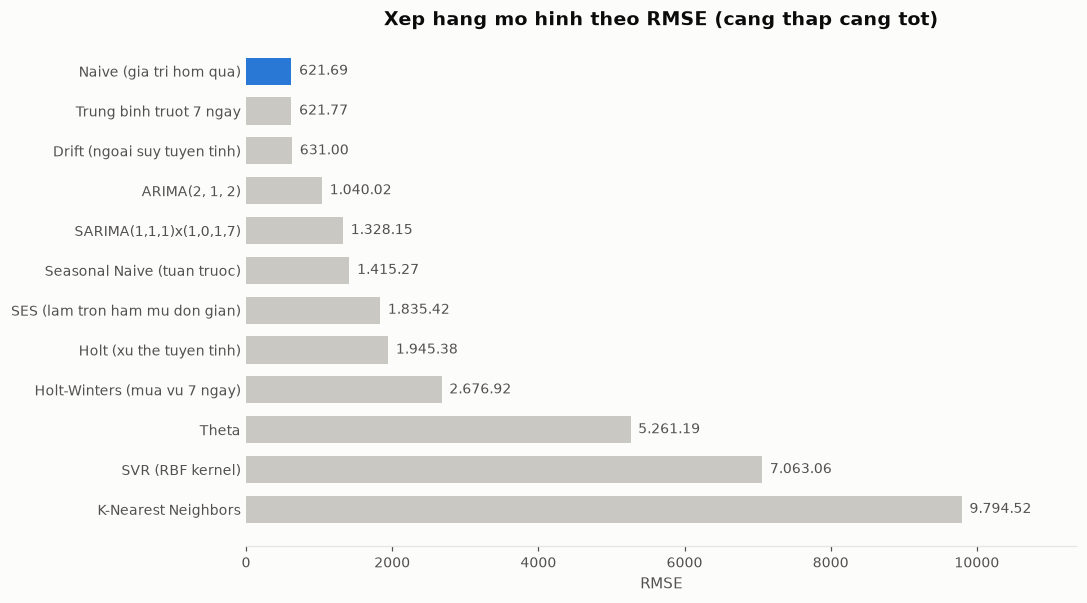

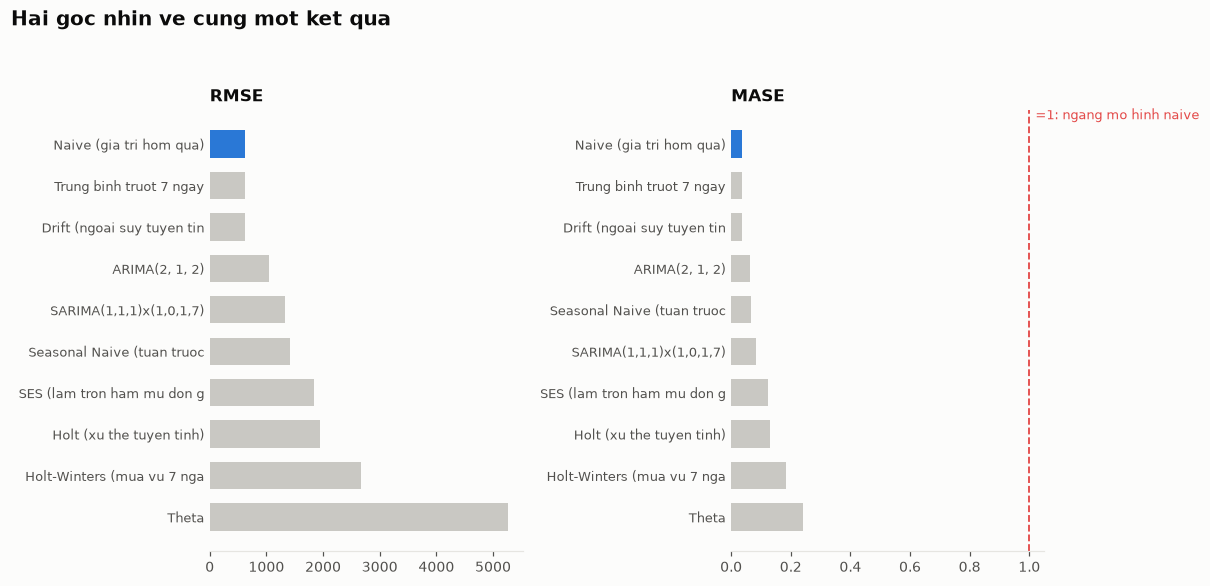

In [17]:
fig = plots.plot_leaderboard(kq_holdout["bang"], metric="RMSE", top=12)
fig = plots.plot_metric_pair(kq_holdout["bang"], left="RMSE", right="MASE", top=10)

Hai panel riêng cho RMSE và MASE là cố ý: không bao giờ chồng hai trục y khác đơn vị lên
cùng một hình. Nếu thứ hạng theo RMSE và theo MASE khác nhau nhiều thì kết luận "mô hình X
tốt nhất" phụ thuộc vào chỉ số bạn chọn — phải nói rõ chọn chỉ số nào và tại sao.

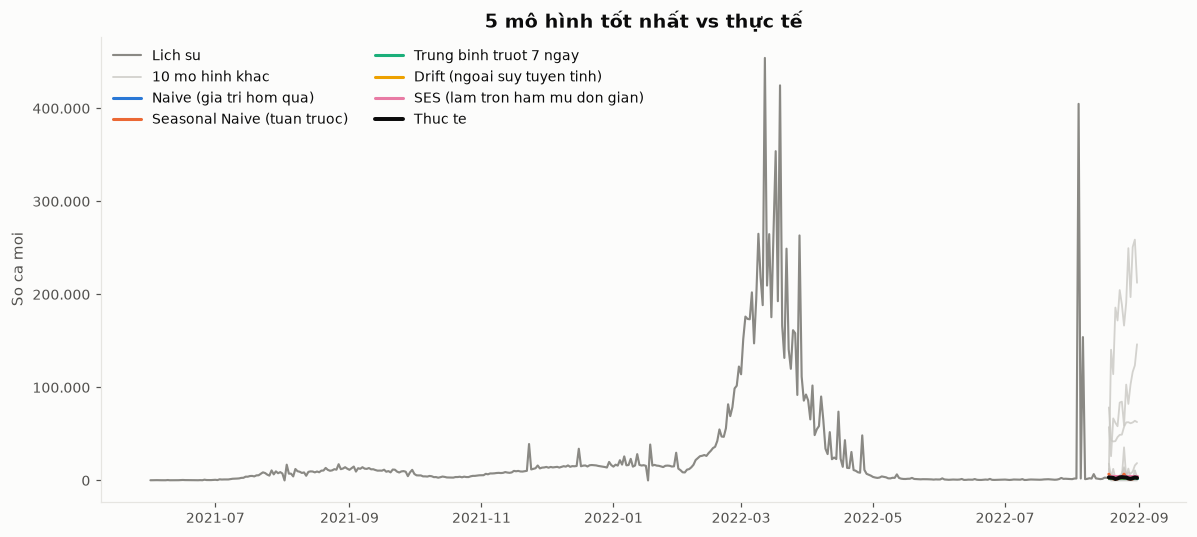

In [18]:
fig = plots.plot_model_comparison(kq_holdout["thuc_te"], kq_holdout["du_bao"],
                                  top=5, context=y,
                                  title="5 mô hình tốt nhất vs thực tế")

## 6. Rolling-origin backtest (kết quả đáng tin hơn)

Holdout chỉ đánh giá trên **một** đoạn 14 ngày — nếu đoạn đó rơi đúng lúc dịch đang phẳng
thì mọi mô hình đều trông giỏi. Rolling-origin trượt điểm cắt nhiều lần:

```
[== train ==][test]
[==== train ====][test]
[====== train ======][test]
```

rồi lấy trung bình, nên bao phủ cả giai đoạn sóng lên, sóng xuống và phẳng.

In [19]:
kq_rolling = backtest.compare_rolling(danh_muc, y, horizon=HORIZON,
                                      n_splits=N_SPLITS, expanding=True, sort_by="MASE")
kq_rolling["bang"]

  [v] Naive (gia tri hom qua)                    RMSE=  23365.49  MASE= 0.702  (0.02s)
  [v] Seasonal Naive (tuan truoc)                RMSE=  23549.83  MASE= 0.708  (0.02s)
  [v] Trung binh truot 7 ngay                    RMSE=  23421.31  MASE= 0.706  (0.02s)
  [v] Drift (ngoai suy tuyen tinh)               RMSE=  23365.66  MASE= 0.702  (0.02s)
  [v] SES (lam tron ham mu don gian)             RMSE=  23642.15  MASE= 0.721  (0.04s)
  [v] Holt (xu the tuyen tinh)                   RMSE=  23645.04  MASE= 0.721  (0.11s)
  [v] Holt-Winters (mua vu 7 ngay)               RMSE=  24985.98  MASE= 0.789  (0.58s)
  [v] Theta                                      RMSE=  25551.03  MASE= 0.808  (0.08s)
  [v] ARIMA(2, 1, 2)                             RMSE=  23481.80  MASE= 0.708  (0.68s)
  [v] SARIMA(1,1,1)x(1,0,1,7)                    RMSE=  23520.33  MASE= 0.711  (0.74s)
  [v] Ridge (hoi quy tuyen tinh)                 RMSE=  41180.44  MASE= 1.919  (0.32s)
  [v] K-Nearest Neighbors                  

,MAE,RMSE,MAPE,sMAPE,R2,MASE,Bias,Giay
Mo hinh,,,,,,,,
Naive (gia tri hom qua),8341.343,23365.495,28.668,30.419,-0.193,0.702,8011.086,0.02
Drift (ngoai suy tuyen tinh),8341.692,23365.656,29.100,30.459,-0.200,0.702,7986.381,0.02
Trung binh truot 7 ngay,8384.024,23421.306,27.628,32.774,-0.364,0.706,8180.857,0.02
Seasonal Naive (tuan truoc),8424.057,23549.826,25.481,30.854,-0.989,0.708,8180.857,0.02
"ARIMA(2, 1, 2)",8422.347,23481.803,28.208,33.444,-0.581,0.708,8236.807,0.68
"SARIMA(1,1,1)x(1,0,1,7)",8465.611,23520.332,28.463,35.711,-0.862,0.711,8370.448,0.74
SES (lam tron ham mu don gian),8600.534,23642.151,36.752,36.919,-1.832,0.721,7808.148,0.04
Holt (xu the tuyen tinh),8603.374,23645.040,37.164,36.283,-1.998,0.721,7728.675,0.11
K-Nearest Neighbors,9441.491,25317.982,68.807,53.890,-50.810,0.783,7331.006,0.37


In [20]:
# Thứ hạng có đổi giữa hai sơ đồ đánh giá không?
h = kq_holdout["bang"]["RMSE"].rank()
r = kq_rolling["bang"]["RMSE"].rank()
so_sanh = pd.DataFrame({"hạng_holdout": h, "hạng_rolling": r}).dropna()
so_sanh["đổi_hạng"] = (so_sanh["hạng_holdout"] - so_sanh["hạng_rolling"]).astype(int)
print("Tương quan hạng Spearman:",
      round(so_sanh["hạng_holdout"].corr(so_sanh["hạng_rolling"], method="spearman"), 3))
so_sanh.sort_values("hạng_rolling")

Tương quan hạng Spearman: 0.979


,hạng_holdout,hạng_rolling,đổi_hạng
Mo hinh,,,
Naive (gia tri hom qua),1.0,1.0,0
Drift (ngoai suy tuyen tinh),3.0,2.0,1
Trung binh truot 7 ngay,2.0,3.0,-1
"ARIMA(2, 1, 2)",4.0,4.0,0
"SARIMA(1,1,1)x(1,0,1,7)",5.0,5.0,0
Seasonal Naive (tuan truoc),6.0,6.0,0
SES (lam tron ham mu don gian),7.0,7.0,0
Holt (xu the tuyen tinh),8.0,8.0,0
SVR (RBF kernel),11.0,9.0,2


Nếu tương quan hạng thấp (< ~0.7), nghĩa là **xếp hạng từ holdout gần như vô giá trị** —
đây là lý do chính để không bao giờ chốt mô hình chỉ dựa trên một lần cắt.

In [21]:
tot_nhat = backtest.best_model(kq_rolling, metric="MASE")
print("Mô hình tốt nhất theo rolling-origin (MASE):", tot_nhat)

kq_rolling["tung_fold"][tot_nhat]

Mô hình tốt nhất theo rolling-origin (MASE): Naive (gia tri hom qua)


,fold,cat_tai,co_train,MAE,RMSE,MAPE,sMAPE,R2,MASE,Bias
0,1,2022-06-23,387,238.857,296.493,32.309,27.456,-0.255,0.018,-133.714
1,2,2022-07-07,401,176.643,233.043,23.257,20.316,-0.010,0.014,-23.500
2,3,2022-07-21,415,481.429,618.633,28.845,32.855,-0.550,0.039,368.571
3,4,2022-08-04,429,40281.000,115057.618,35.933,51.284,-0.137,3.403,39915.000
4,5,2022-08-18,443,528.786,621.690,22.994,20.185,-0.013,0.038,-70.929


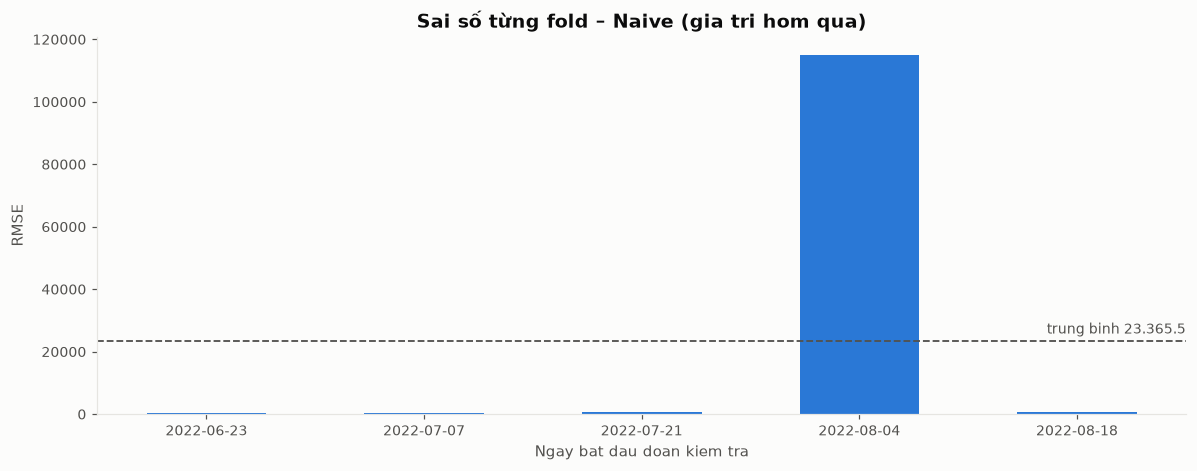

In [22]:
fig = plots.plot_backtest_folds(y, kq_rolling["tung_fold"][tot_nhat], metric="RMSE",
                                title=f"Sai số từng fold – {tot_nhat}")

Bảng từng fold quan trọng hơn con số trung bình: nó cho thấy mô hình **ổn định** hay chỉ
tốt ở một giai đoạn. RMSE chênh nhau hàng chục lần giữa các fold là chuyện bình thường với
dữ liệu dịch — fold rơi vào lúc bùng dịch luôn tệ hơn hẳn fold rơi vào lúc dịch phẳng.

Nếu **một** fold có sai số lớn gấp hàng chục lần các fold còn lại, hãy kiểm tra lại dữ liệu
trước khi đổ lỗi cho mô hình: gần như chắc chắn đoạn test đó chứa một ngày dồn số liệu hồi tố
(xem bảng ngày bất thường ở §1). Không mô hình nào dự báo được một quyết định hành chính.

## 7. Chẩn đoán phần dư

Phần dư $e = \text{thực tế} - \text{dự báo}$ của một mô hình tốt phải: dao động quanh 0,
không còn xu thế, không tự tương quan, và xấp xỉ phân phối chuẩn. Nếu ACF của phần dư còn
gai vượt ngưỡng → vẫn còn cấu trúc mà mô hình chưa khai thác hết.

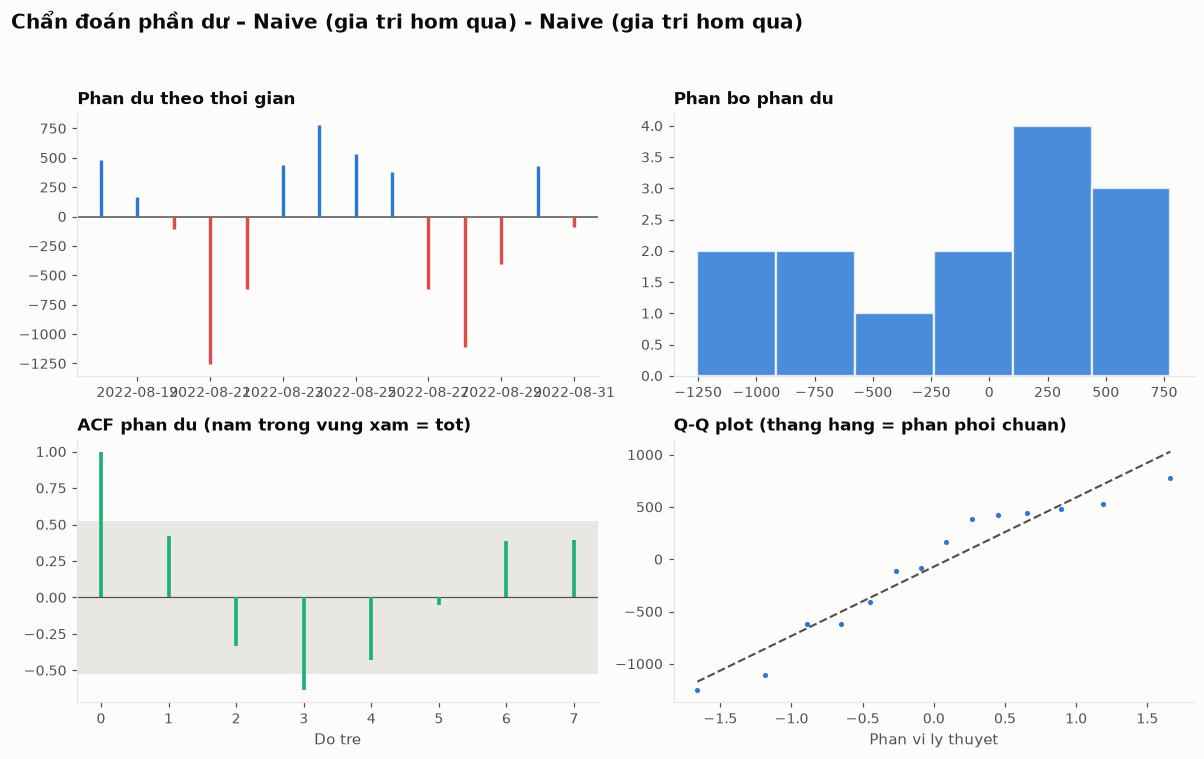

In [23]:
ct = kq_holdout["chi_tiet"].get(tot_nhat) or next(iter(kq_holdout["chi_tiet"].values()))
fig = plots.plot_residuals(ct["thuc_te"], ct["du_bao"],
                           title=f"Chẩn đoán phần dư – {ct['ten']}")

## 8. Ensemble 3 mô hình đầu bảng

Trung bình dự báo của nhiều mô hình thường ổn định hơn từng mô hình riêng lẻ: các sai số
lệch chiều nhau triệt tiêu bớt. Đây là mẹo rẻ tiền nhưng hiệu quả trong hầu hết cuộc thi
dự báo.

In [24]:
top3 = [t for t in kq_rolling["bang"].index[:3]]
ens = models.EnsembleForecaster([danh_muc[t] for t in top3],
                                name="Ensemble top-3")
print("Thành phần:", top3)

kq_ens = backtest.rolling_backtest(ens, y, horizon=HORIZON, n_splits=N_SPLITS)
pd.DataFrame({
    "Ensemble": kq_ens["trung_binh"],
    top3[0]: kq_rolling["bang"].loc[top3[0]].drop("Giay", errors="ignore"),
}).round(3)

Thành phần: ['Naive (gia tri hom qua)', 'Drift (ngoai suy tuyen tinh)', 'Trung binh truot 7 ngay']


,Ensemble,Naive (gia tri hom qua)
MAE,8347.848,8341.343
RMSE,23380.174,23365.495
MAPE,27.818,28.668
sMAPE,30.545,30.419
R2,-0.216,-0.193
MASE,0.703,0.702
Bias,8059.441,8011.086


## 9. Dự báo tương lai thật sự

Bước cuối: huấn luyện lại mô hình đã chọn trên **toàn bộ** dữ liệu rồi dự báo `HORIZON`
ngày tiếp theo. Lúc này không còn giá trị thực để đối chiếu — nên khoảng tin cậy mới là
thứ đáng nhìn, không phải đường trung tâm.

In [25]:
du_bao = backtest.refit_and_forecast(danh_muc[tot_nhat], y, horizon=HORIZON)
du_bao.round(1)

,du_bao,can_duoi,can_tren
ngay,,,
2022-09-01,2727.0,0.0,85215.9
2022-09-02,2727.0,0.0,119383.9
2022-09-03,2727.0,0.0,145602.0
2022-09-04,2727.0,0.0,167704.8
2022-09-05,2727.0,0.0,187177.8
2022-09-06,2727.0,0.0,204782.7
2022-09-07,2727.0,0.0,220972.1
2022-09-08,2727.0,0.0,236040.8
2022-09-09,2727.0,0.0,250193.7


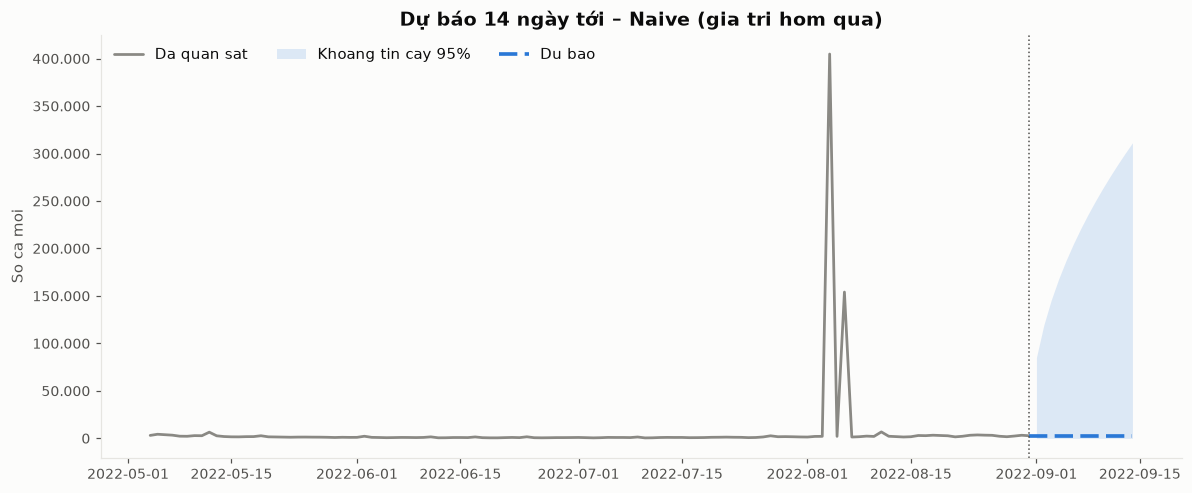

In [26]:
fig = plots.plot_fan(y, du_bao, context=120,
                     title=f"Dự báo {HORIZON} ngày tới – {tot_nhat}")

⚠️ **Đọc kỹ dải tin cậy.** Với hầu hết mô hình ở đây, khoảng dự báo mặc định được ước lượng
từ độ lệch chuẩn phần dư trên **toàn bộ** tập huấn luyện (`Forecaster.predict_interval`).
Nếu tập huấn luyện chứa cả đỉnh dịch, độ lệch chuẩn đó khổng lồ, và dải tin cậy cho một giai
đoạn đang phẳng sẽ rộng đến mức vô dụng (kiểu "từ 0 đến 100 000 ca" cho dự báo 2 700 ca).
Đó cũng là lý do `Coverage95` hay bằng đúng 100% — không phải vì khoảng chính xác, mà vì nó
quá rộng để có thể sai. Muốn nghiêm túc thì dùng khoảng riêng của ARIMA/ETS/Prophet, hoặc
ước lượng lại phần dư chỉ trên cửa sổ gần nhất.

## 10. Lưu kết quả

In [27]:
kq_holdout["bang"].to_csv(OUT_RES / "leaderboard_holdout.csv", encoding="utf-8-sig")
kq_rolling["bang"].to_csv(OUT_RES / "leaderboard_rolling.csv", encoding="utf-8-sig")
du_bao.to_csv(OUT_RES / f"du_bao_{COUNTRY}_{HORIZON}ngay.csv", encoding="utf-8-sig")

# Lưu hình: mọi hàm plot_* đều trả về Figure nên có thể lưu bất cứ lúc nào
plots.save(plots.plot_fan(y, du_bao, context=120), f"du_bao_{COUNTRY}.png")
plots.save(plots.plot_leaderboard(kq_rolling["bang"], metric="MASE", top=12),
           "xep_hang_rolling.png")

import matplotlib.pyplot as plt
plt.close("all")          # tránh hiển thị trùng hình vừa lưu

print("Đã lưu vào:", OUT_RES.parent)

Đã lưu vào: /mnt/datassd/CodeHub/Science/WILD/DataMining/7/outputs


## 11. Nhận xét

**1. Baseline rất khó bị đánh bại.** Với chuỗi ca nhiễm theo ngày, phần lớn thông tin nằm ở
giá trị hôm qua. Naive và Drift thường xếp trên cả ARIMA lẫn XGBoost ở tầm nhìn ngắn. Đây
không phải lỗi cài đặt — đây là kết quả đã được lặp lại nhiều lần trong tài liệu về dự báo
dịch tễ. Nếu mô hình phức tạp của bạn chỉ ngang naive, kết luận trung thực là "mô hình phức
tạp không mang lại giá trị gia tăng ở đây", chứ không phải đi tinh chỉnh đến khi thắng.

**2. Mô hình học máy đuối ở dự báo nhiều bước.** `MLForecaster` dự báo **đệ quy**: dự báo
t+1 → nối vào lịch sử → dự báo t+2… Sai số tích luỹ qua 14 bước. Cây quyết định (RF, GB, XGB)
còn thêm một nhược điểm chí mạng: **không ngoại suy được ra ngoài miền giá trị đã thấy trong
train**, nên khi dịch bùng lên mức chưa từng có, chúng luôn dự báo thấp.

**3. MASE ở đây nhỏ bất thường.** Mẫu số của MASE là sai số naive trên tập train; tập train
chứa đỉnh dịch với biến động hàng chục nghìn ca/ngày, nên mẫu số rất lớn và MASE bị đẩy về
gần 0 khi tập test rơi vào giai đoạn phẳng. **MASE < 1 ở đây không chứng minh mô hình giỏi** —
chỉ chứng minh giai đoạn test yên ả hơn giai đoạn train.

**4. Bản thân dữ liệu là điểm yếu lớn nhất.** Số ca xác nhận phụ thuộc vào năng lực xét
nghiệm và chính sách báo cáo, không phải số ca nhiễm thật. Các ngày âm do điều chỉnh hồi tố
đã bị cắt về 0 — tức là ta đã bóp méo dữ liệu một chút để mô hình chạy được.

**Hướng mở rộng nếu cần làm sâu hơn:**

- Dự báo trên thang `log1p` rồi biến đổi ngược (`analysis.log_transform` / `inverse_log`) —
  ổn định phương sai, thường cải thiện rõ ở giai đoạn tăng theo cấp số nhân
- So sánh cùng một danh mục trên nhiều quốc gia để xem thứ hạng có ổn định không
- Dự báo trực tiếp nhiều bước (direct multi-step: mỗi horizon một mô hình riêng) thay vì đệ quy
- Thay dải tin cậy mặc định bằng conformal prediction cho khoảng có bảo đảm hợp lệ